# 임베딩과 벡터스토어

**이 노트북에서 할 일**

1. 01·02절과 같은 E01 문서 청크 8개를 빈 벡터스토어에 넣고, 저장된 벡터와 메타데이터를 봅니다.
2. 점수와 함께 검색하고, 그 점수를 Ch 5 02절 코사인 유사도를 NumPy로 직접 계산한 값과 비교합니다.
3. 두 가지를 함께 묻는 질문에서 k=1로 근거 하나가 빠지는 Before와, k를 3으로 늘린 After를 비교합니다.

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 데이터 파일은 `labs/data/rag-corpus/pdf/easy/E01.pdf`입니다.

인터넷 서비스에 요청을 모두 6번 보냅니다. 모두 임베딩 모델 `text-embedding-3-small`에 보내고, 답을 쓰는 모델은 부르지 않습니다.
실행 시간은 1분 안팎이고, 예상 비용은 0.001달러 미만으로 잡았습니다.
임베딩 요금은 OpenAI 모델 안내(2026-09-17 확인)에 적힌 100만 토큰당 0.02달러입니다.
라이브러리 tiktoken은 처음 실행할 때 토큰화 규칙 파일을 인터넷에서 내려받습니다.

**강의와 실습 범위** — 강의 시간에는 3~5절(벡터스토어에 넣기, 점수와 함께 검색, 코사인 유사도로 확인)을 설명합니다. 2절은 01·02절과 같은 코드라 강의에서 빠르게 확인합니다.
6절 값 바꿔 보기와 Before·After는 함께 실행하고 실습 시간에 읽습니다.

**기준 버전** — 실습 폴더에 고정한 판을 씁니다. langchain-core 1.6.2, langchain-openai 1.6.0입니다.
함께 쓰는 판은 pypdf 6.17.0과 langchain-text-splitters 1.1.2입니다. 토큰을 세는 tiktoken은 0.14.0입니다.
numpy 2.5.3은 5절 코사인 유사도 계산과 벡터스토어 점수 계산에 쓰고, openai 판은 3.8.0입니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch09-rag-first-run`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위 칸 넣기에는 초록 상자 문서 청크 8개 2885토큰, 보라 상자 text-embedding-3-small 요청 1번, 초록 상자 저장 항목 8개 id vector 1536 text metadata가 왼쪽에서 오른쪽으로 있고, 위 칸에서 아래 칸으로 저장 벡터 8개 화살표가 내려오며, 아래 칸 검색에는 초록 상자 질문 한 문장, 보라 상자 질문 임베딩 숫자 1536개, 파란 상자 코사인 유사도가 큰 순서로 k=2, 노란 상자 E01 p.1 0.5833과 E01 p.2 0.574이 왼쪽에서 오른쪽으로 있는 흐름도](attachment:03-1-넣기와-점수-검색.png)

위 칸은 문서 청크를 임베딩해 벡터스토어에 넣는 단계, 아래 칸은 질문과 점수를 함께 받는 검색 단계입니다.
초록 상자는 코드가 만든 자료, 보라 상자는 임베딩 모델, 파란 상자는 코드 단계, 노란 상자는 출력으로 확인할 값입니다.
노트북 3절이 위 칸, 4·5절이 아래 칸을 실행합니다.
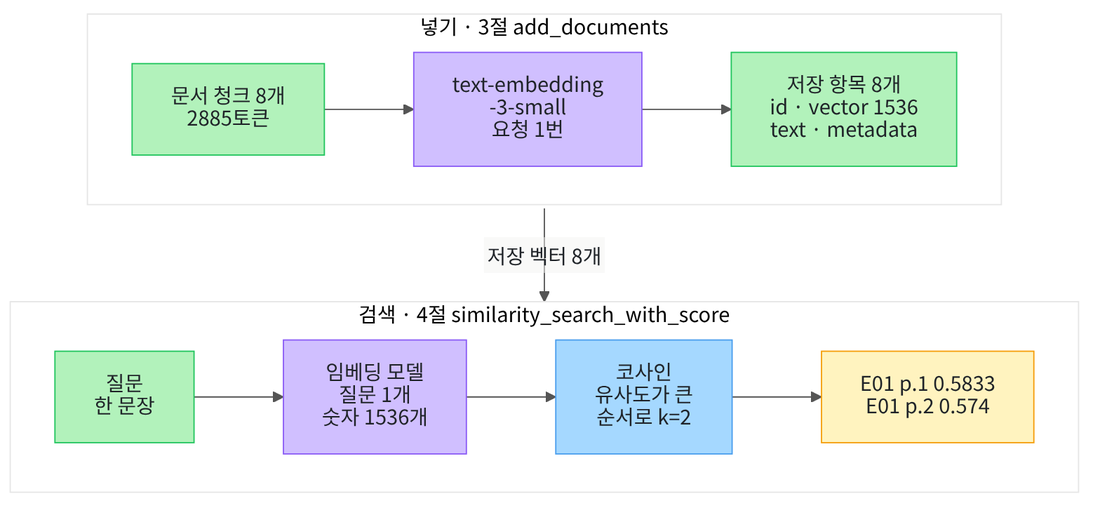

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
01절과 같은 임베딩·벡터스토어 패키지에, 02절에서 쓴 tiktoken을 함께 씁니다. 답을 쓰는 모델은 이 노트북에서 부르지 않습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "pypdf==6.17.0" "langchain==1.4.0" "langchain-openai==1.6.0" "langchain-text-splitters==1.1.2" "python-dotenv==1.2.3" "tiktoken==0.14.0" "numpy==2.5.3"
from importlib.metadata import version

print("pypdf:", version("pypdf"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("langchain-text-splitters:", version("langchain-text-splitters"))
print("tiktoken:", version("tiktoken"))
print("numpy:", version("numpy"))
print("openai:", version("openai"))

Note: you may need to restart the kernel to use updated packages.
pypdf: 6.17.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
langchain-text-splitters: 1.1.2


tiktoken: 0.14.0
numpy: 2.5.3
openai: 3.8.0


**결과 읽기** — 출력 줄은 `langchain-core: 1.6.2`, `langchain-openai: 1.6.0`, `numpy: 2.5.3` 등 일곱 줄입니다.
준비물에 적은 기준 버전과 같습니다.

문서 청크 나누기, 토큰 세기, 임베딩, 벡터스토어, 벡터 계산에 쓸 이름을 불러옵니다.
패키지 NumPy는 Ch 5 02절에서 코사인 유사도를 계산할 때 쓴 패키지이고, 같은 짧은 이름 `np`로 불러옵니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 02절 `load_pdf_pages()`, Ch 8 01절 `count_tokens()`, Ch 8 03절 `find_missing_words()`를 가져옵니다.

In [2]:
# 문서 청크 나누기·토큰 세기·임베딩·벡터스토어·벡터 계산에 쓸 이름을 불러옵니다
import os

import numpy as np
from langchain_text_splitters import RecursiveCharacterTextSplitter
import tiktoken
from langchain_openai import OpenAIEmbeddings
from langchain_core.vectorstores import InMemoryVectorStore
# 02절과 Ch 8 01·03절 함수 세 개를 도구 파일에서 가져옵니다
from rag_tools import count_tokens, find_missing_words, load_pdf_pages

01절과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄은 `OPENAI_API_KEY 설정 여부: True`입니다.

## 2. 01·02절과 같은 문서 청크 만들기

이 노트북은 01·02절과 같은 E01 문서 청크 8개로 시작합니다. 경로를 고르는 셀은 01·02절과 같은 코드입니다.
실행 전에 예상합니다. 프로젝트 맨 위에서 열었다면 첫째 후보를 고를 것입니다.

In [4]:
# 작업 폴더에서 본 E01.pdf 경로를 후보 세 개 가운데에서 고릅니다
candidates = [
    "labs/data/rag-corpus/pdf/easy/E01.pdf",
    "../../data/rag-corpus/pdf/easy/E01.pdf",
    "../../../data/rag-corpus/pdf/easy/E01.pdf",
]
pdf_path = None
for candidate in candidates:
    if os.path.exists(candidate):
        pdf_path = candidate
        break
print("PDF를 찾았는가:", pdf_path is not None)
print("고른 경로:", pdf_path)
assert pdf_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

PDF를 찾았는가: True
고른 경로: labs/data/rag-corpus/pdf/easy/E01.pdf


**결과 읽기** — 출력 줄은 `PDF를 찾았는가: True`와 `고른 경로: labs/data/rag-corpus/pdf/easy/E01.pdf`입니다.
교재 출력은 프로젝트 맨 위를 작업 폴더로 삼아 실행해서 첫째 후보를 골랐습니다.
`notebooks` 폴더에서 열면 셋째 후보가 나옵니다.

준비 셀에서 가져온 02절 로더 함수 `load_pdf_pages()`는 PDF 경로와 문서 이름을 받아, 쪽마다 Document를 담은 목록을 반환합니다.

로더 함수로 다섯 쪽을 읽고, 01·02절과 같은 설정인 크기 500자·겹침 50자로 나눕니다.
실행 전에 예상합니다. 02절처럼 문서 청크 8개가 나올 것입니다.

In [5]:
# E01.pdf를 쪽마다 읽고, 01·02절과 같은 설정으로 문서 청크를 나눕니다
pages = load_pdf_pages(pdf_path, "E01")
splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)
chunks = splitter.split_documents(pages)
print("Document 수:", len(pages))
print("문서 청크 수:", len(chunks))
print("문서 청크(쪽 | 글자 수):")
for chunk in chunks:
    print(chunk.metadata["page"], "|", len(chunk.page_content))

Document 수: 5
문서 청크 수: 8
문서 청크(쪽 | 글자 수):
1 | 45
2 | 498
2 | 452
3 | 498
3 | 462
4 | 492
4 | 412
5 | 270


**결과 읽기** — 출력 줄은 `Document 수: 5`와 `문서 청크 수: 8`입니다. 라벨 줄 아래 여덟 줄은 `1 | 45`부터 `5 | 270`까지입니다.
2쪽 두 줄 `2 | 498`과 `2 | 452`도 01·02절 출력과 같습니다.

## 3. 문서 청크를 임베딩해 벡터스토어에 넣기

01절에서는 `InMemoryVectorStore.from_documents()` 한 줄로 임베딩과 저장을 함께 했습니다.
이번에는 그 한 줄을 나눠 봅니다. 임베딩 객체 만들기, 빈 벡터스토어 만들기, 문서 청크 넣기 순서입니다.

먼저 02절과 같은 모델 이름 `embedding_model_name`으로 임베딩 객체를 만듭니다. 객체 이름은 01절과 같은 `embedding_model`입니다.
클래스 `OpenAIEmbeddings`는 모델 설정을 담은 객체를 반환하고, 이 셀은 요청을 보내지 않습니다.
같은 셀에서 02절과 같은 토큰화 규칙도 불러옵니다.

In [6]:
# 02절과 같은 모델 이름으로 임베딩 객체와 토큰화 규칙을 준비합니다(요청은 보내지 않습니다)
embedding_model_name = "text-embedding-3-small"
embedding_model = OpenAIEmbeddings(model=embedding_model_name)
encoding = tiktoken.encoding_for_model(embedding_model_name)
print("임베딩 모델 이름:", embedding_model.model)
print("토큰화 규칙 이름:", encoding.name)

임베딩 모델 이름: text-embedding-3-small
토큰화 규칙 이름: cl100k_base


**결과 읽기** — 출력 줄은 `임베딩 모델 이름: text-embedding-3-small`과 `토큰화 규칙 이름: cl100k_base`입니다.
이 노트북의 출력은 2026-09-21에 이 임베딩 모델로 실행한 결과입니다. 검색 점수는 실행마다 조금 달라질 수 있습니다.

규칙 `cl100k_base`는 02절에서 본 임베딩 모델의 규칙입니다. 답 모델 `gpt-5.4-mini`의 `o200k_base`와 다릅니다.
임베딩 요금은 보내는 토큰 수로 매기므로, 넣기 전에 문서 청크의 토큰 수를 셉니다.
토큰 수는 02절처럼 준비 셀에서 가져온 `count_tokens()`에 토큰화 규칙 객체와 글을 넘겨 셉니다.

문서 청크 8개의 토큰 수를 더하고, 100만 토큰당 0.02달러로 색인 비용을 어림합니다.
계산에 쓰는 숫자는 이름 있는 변수에 먼저 담습니다. 아주 작은 값이라 `round()`로 소수 일곱째 자리까지 줄입니다.
실행 전에 예상합니다. 02절 4절에서 본 토큰 수를 모두 더한 값이 나올 것입니다.

In [7]:
# 문서 청크 8개의 토큰 수를 더하고, 100만 토큰당 0.02달러로 색인 비용을 어림합니다
total_tokens = 0
for chunk in chunks:
    total_tokens = total_tokens + count_tokens(encoding, chunk.page_content)
embedding_rate = 0.02
tokens_per_million = 1000000
raw_cost = total_tokens * embedding_rate / tokens_per_million
index_cost = round(raw_cost, 7)
print("넣을 토큰 수 합계:", total_tokens)
print("색인 비용 어림(달러):", index_cost)

넣을 토큰 수 합계: 2885
색인 비용 어림(달러): 5.77e-05


**결과 읽기** — 출력 줄은 `넣을 토큰 수 합계: 2885`와 `색인 비용 어림(달러): 5.77e-05`입니다.

표기 `e-05`는 앞 수를 10으로 다섯 번 나눈 값이라는 뜻입니다. 곧 0.0000577달러입니다.
합계 2885는 02절 4절에서 센 여덟 토큰 수를 모두 더한 값입니다. 요청 전에 코드로 센 어림이고, 청구 금액이 아닙니다.

빈 벡터스토어를 만듭니다. 클래스 `InMemoryVectorStore`에 임베딩 객체를 넣으면, 저장 항목이 하나도 없는 벡터스토어를 반환합니다.
메서드 `add_documents()`는 Document 목록을 받아 본문을 임베딩하고, 벡터와 함께 저장합니다.

반환값은 저장 ID 목록입니다. 저장 ID는 저장 항목마다 붙는 이름입니다.
실행 전에 예상합니다. 저장 ID는 문서 청크 수만큼 나올 것입니다.

In [8]:
# 빈 벡터스토어를 만들고, 문서 청크 8개를 임베딩해 넣습니다(임베딩 요청 1번)
store = InMemoryVectorStore(embedding=embedding_model)
print("넣기 전 저장 항목 수:", len(store.store))
stored_ids = store.add_documents(chunks)
print("넣은 뒤 저장 항목 수:", len(store.store))
print("저장 ID 수:", len(stored_ids))
print("첫 저장 ID:", stored_ids[0])

넣기 전 저장 항목 수: 0
넣은 뒤 저장 항목 수: 8
저장 ID 수: 8
첫 저장 ID: 6e6e9e89-a1a5-48bd-b136-9690246db461


**결과 읽기** — 출력 줄은 `넣기 전 저장 항목 수: 0`, `넣은 뒤 저장 항목 수: 8`, `저장 ID 수: 8`입니다.
마지막 줄의 첫 저장 ID는 영문자와 숫자, 빼기 표시로 된 긴 글입니다.

설치한 langchain-core 1.6.2 소스에서 이 ID는 넣을 때마다 새로 만드는 무작위 글(uuid4)입니다. 실행마다 달라지므로 비교에 쓰지 않습니다.
여덟 문서 청크는 한 요청으로 함께 임베딩했습니다. 01절 `from_documents()`도 소스에서는 빈 벡터스토어를 만든 뒤 문서를 넣는 같은 순서입니다.

저장 항목 하나를 열어 봅니다. 01절에서 개수만 센 속성 `store`는 저장 ID를 키로 삼는 딕셔너리입니다.
2쪽 첫 문서 청크는 목록에서 둘째이므로 `stored_ids[1]`로 항목을 꺼냅니다.
실행 전에 예상합니다. 벡터 옆에 본문과 메타데이터가 함께 있을 것입니다.

In [9]:
# 2쪽 첫 문서 청크의 저장 항목을 꺼내 키, 벡터 길이, 메타데이터, 본문 앞부분을 봅니다
stored_item = store.store[stored_ids[1]]
stored_vector = stored_item["vector"]
print("저장 항목의 키:", stored_item.keys())
print("벡터의 숫자 개수:", len(stored_vector))
print("메타데이터:", stored_item["metadata"])
front_text = stored_item["text"][:20].replace("\n", " ")
print("본문 앞 20자:", front_text)

저장 항목의 키: dict_keys(['id', 'vector', 'text', 'metadata'])
벡터의 숫자 개수: 1536
메타데이터: {'doc_id': 'E01', 'page': 2, 'source': 'E01.pdf'}
본문 앞 20자: 1. 도서관 소개 미르시립도서관은 1


**결과 읽기** — 첫 줄은 `저장 항목의 키: dict_keys(['id', 'vector', 'text', 'metadata'])`이고, 둘째 줄은 `벡터의 숫자 개수: 1536`입니다.
셋째 줄은 `메타데이터: {'doc_id': 'E01', 'page': 2, 'source': 'E01.pdf'}`, 넷째 줄은 `본문 앞 20자: 1. 도서관 소개 미르시립도서관은 1`입니다.

저장 항목 하나에 저장 ID, 벡터, 본문, 메타데이터가 함께 들어 있습니다. 벡터 길이 1536은 01절 질문 벡터와 같습니다.
문서 청크의 벡터는 넣을 때 한 번 만들어 둡니다. 설치한 1.6.2 소스에서 검색할 때 새로 임베딩하는 것은 질문뿐입니다.

## 4. 점수와 함께 검색하기

01절 5절에서는 메서드 `similarity_search()`로 문서 청크만 받았습니다. 이번에는 `similarity_search_with_score()`로 점수까지 받습니다.
반환값은 목록이고, 원소 하나는 Document와 점수 두 값을 묶은 튜플입니다.
설치한 1.6.2 소스에서 점수는 질문 벡터와 저장 벡터의 코사인 유사도이고, 큰 순서로 k개를 고릅니다.

튜플 두 값은 반복문 `for hit, score in scored_hits:`에서 두 이름에 나눠 담습니다. Ch 5 02절에서 문장 쌍을 두 이름으로 나눠 읽은 모양과 같습니다.
출처 표시는 여러 셀에서 만드므로, 01절 코드를 함수 `make_source_mark()`로 묶습니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [10]:
# 문서 청크 하나를 받아 메타데이터로 [E01 p.2] 모양의 출처 표시를 만들어 반환하는 함수를 정의합니다
def make_source_mark(chunk):
    doc_id = chunk.metadata["doc_id"]
    page = chunk.metadata["page"]
    source_mark = f"[{doc_id} p.{page}]"
    return source_mark

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

01절과 같은 휴관일 질문으로, 01절과 같은 k=2 검색을 점수와 함께 합니다. 점수는 Ch 5 02절처럼 `round()`로 소수 넷째 자리까지 줄여 출력합니다.
실행 전에 예상합니다. 01절처럼 표지가 1위, 2쪽이 2위이고, 두 점수는 가까울 것입니다.

In [11]:
# 01절과 같은 질문으로 문서 청크 2개를 점수와 함께 검색합니다(임베딩 요청 1번)
question_text = "미르시립도서관의 정기 휴관일은 언제이고, 공휴일이 월요일과 겹치면 어떻게 되나요?"
scored_hits = store.similarity_search_with_score(question_text, k=2)
print("반환값의 원소 수:", len(scored_hits))
print("첫 원소의 자료형:", type(scored_hits[0]))
print("k=2 검색 결과(출처 | 글자 수 | 점수):")
for hit, score in scored_hits:
    print(make_source_mark(hit), "|", len(hit.page_content), "|", round(score, 4))

반환값의 원소 수: 2
첫 원소의 자료형: <class 'tuple'>
k=2 검색 결과(출처 | 글자 수 | 점수):
[E01 p.1] | 45 | 0.5833
[E01 p.2] | 498 | 0.574


**결과 읽기** — 출력 줄은 `반환값의 원소 수: 2`와 `첫 원소의 자료형: <class 'tuple'>`입니다.
라벨 줄 아래 첫 줄은 `[E01 p.1] | 45 | 0.5833`, 둘째 줄은 `[E01 p.2] | 498 | 0.574`입니다.

출처 순서는 01절 5절 결과와 같습니다. 두 점수의 차이는 0.01보다 작습니다.
휴관 문장이 든 2쪽 문서 청크는 이용 시간 같은 다른 글도 많이 담고 있습니다. 표지는 45자로 짧고, 질문에 나온 도서관 이름이 들어 있습니다.
점수는 뜻이 가까운 정도이고, 답이 들어 있는지를 판정한 값이 아닙니다.

## 5. 점수를 코사인 유사도로 직접 계산하기

코사인 유사도는 Ch 5 02절에서 배웠습니다. 두 벡터의 점곱을 두 벡터 길이의 곱으로 나눈 값입니다.
길이와 관계없이 두 벡터의 방향이 얼마나 같은지만 봅니다. 숫자 개수는 1536개로 늘었지만 계산 방법은 같습니다.
Ch 5 02절처럼 NumPy의 `np.array()`·`@`·`np.linalg.norm()`으로 이 식을 적습니다.

질문을 01절 4절처럼 `embed_query()`로 임베딩해 질문 벡터를 만듭니다. 설치한 1.6.2 소스에서 4절 검색도 같은 메서드로 질문을 임베딩합니다.
검색 결과 Document의 속성 `id`에는 저장 ID가 들어 있습니다. 이 ID로 3절 `store`에서 저장 항목을 꺼내 저장 벡터를 씁니다.

실행 전에 예상합니다. 같은 식으로 계산하니 4절 점수와 같은 값이 나올 것입니다.

In [12]:
# Ch 5 02절에서 배운 코사인 유사도를 NumPy로 계산해, 4절 검색 결과의 점수와 나란히 봅니다(임베딩 요청 1번)
question_vector = np.array(embedding_model.embed_query(question_text))
print("출처 | 벡터스토어 점수 | 직접 계산한 코사인 유사도:")
for hit, score in scored_hits:
    stored_vector = np.array(store.store[hit.id]["vector"])
    # 점곱을 두 벡터 길이의 곱으로 나누면 길이와 관계없이 방향만 비교합니다
    dot = question_vector @ stored_vector
    length_product = np.linalg.norm(question_vector) * np.linalg.norm(stored_vector)
    direct_score = dot / length_product
    print(make_source_mark(hit), "|", round(score, 4), "|", round(direct_score, 4))

출처 | 벡터스토어 점수 | 직접 계산한 코사인 유사도:
[E01 p.1] | 0.5833 | 0.5833
[E01 p.2] | 0.574 | 0.574


**결과 읽기** — 라벨 줄 아래 첫 줄은 `[E01 p.1] | 0.5833 | 0.5833`, 둘째 줄은 `[E01 p.2] | 0.574 | 0.574`입니다.

두 문서 청크 모두 벡터스토어 점수와 직접 계산한 값이 소수 넷째 자리까지 같았습니다.
벡터스토어 점수가 Ch 5 02절에서 배운 코사인 유사도라는 것을 이번 실행에서 확인했습니다.
설치한 1.6.2 소스도 같은 식을 NumPy로 한꺼번에 계산합니다.

질문 벡터는 4절 검색과 따로 한 번 더 요청해 만들었습니다. 같은 글을 다시 임베딩해도 숫자가 늘 같다고 보장하지 않습니다.
그래서 두 값이 같은지를 `assert`로 검사하지 않았습니다.

## 6. 값 바꿔 보기 — k를 문서 청크 수 8로 늘리기

바꾸는 값은 가져오는 개수 k 하나입니다. 2를 문서 청크 수와 같은 8로 바꾸고, 질문과 벡터스토어는 그대로 둡니다.

그러면 모든 문서 청크가 점수 순서로 나옵니다. 순위 번호는 반복문 안에서 1씩 늘립니다.
실행 전에 예상합니다. 1·2위는 4절과 같고, 나머지 점수는 그보다 작을 것입니다.

In [13]:
# 같은 질문으로 k만 8로 바꿔, 문서 청크 8개 전체의 순위와 점수를 봅니다(임베딩 요청 1번)
all_hits = store.similarity_search_with_score(question_text, k=8)
print("k=8 검색 결과(순위 | 출처 | 글자 수 | 점수):")
rank = 1
for hit, score in all_hits:
    print(rank, "|", make_source_mark(hit), "|", len(hit.page_content), "|", round(score, 4))
    rank = rank + 1

k=8 검색 결과(순위 | 출처 | 글자 수 | 점수):
1 | [E01 p.1] | 45 | 0.5833
2 | [E01 p.2] | 498 | 0.574
3 | [E01 p.2] | 452 | 0.3833
4 | [E01 p.5] | 270 | 0.3554
5 | [E01 p.3] | 498 | 0.3383
6 | [E01 p.3] | 462 | 0.3367
7 | [E01 p.4] | 412 | 0.3219
8 | [E01 p.4] | 492 | 0.1541


**결과 읽기** — 라벨 줄 아래 여덟 줄입니다. 1·2위 줄은 `1 | [E01 p.1] | 45 | 0.5833`과 `2 | [E01 p.2] | 498 | 0.574`입니다.
3위 줄은 `3 | [E01 p.2] | 452 | 0.3833`, 8위 줄은 `8 | [E01 p.4] | 492 | 0.1541`입니다.

1·2위는 4절과 같았고, 3위부터는 점수가 0.4보다 작았습니다. 이 질문에서는 2위와 3위 사이의 점수 차이가 컸습니다.
가장 낮은 점수도 0보다 큰 0.1541입니다. 「휴관」이라는 말이 없는 4쪽 문서 청크도 점수가 0이 되지는 않습니다.
그래서 점수 하나만 보고 「이보다 낮으면 관계없음」이라고 정할 기준값은 이 노트북에서 알 수 없습니다.

## Before — 두 가지를 묻는 질문을 k=1로 검색하기

이번 질문은 두 가지를 함께 묻습니다. 정기 휴관일과, 도서를 몇 권까지 빌릴 수 있는지입니다.
Ch 8 02절 기록으로 보면 휴관은 E01 2쪽, 대출은 E01 3쪽에 적혀 있습니다. 답하려면 두 쪽의 근거가 모두 필요합니다.

근거가 다 들어왔는지는 사람이 원문에서 고른 지킬 말 「월요일」과 「7권」으로 검사합니다. Ch 8 07절이 요청 전에 근거를 검사한 방법과 같습니다.
검사 함수는 02절처럼 준비 셀에서 가져온 Ch 8 03절 `find_missing_words()`입니다.

개수 k를 1로 두고 검색합니다. 검색한 문서 청크의 본문을 01절 7절처럼 `+`로 이어 근거 글을 만들고, 빠진 지킬 말을 봅니다.
실행 전에 예상합니다. 문서 청크 하나로는 두 쪽의 근거를 모두 담지 못할 것입니다.

In [14]:
# 두 가지를 묻는 질문을 k=1로 검색하고, 근거 글에서 빠진 지킬 말을 봅니다(임베딩 요청 1번)
combined_question = "미르시립도서관의 정기 휴관일은 언제이고, 도서는 몇 권까지 빌릴 수 있나요?"
combined_keep_words = ["월요일", "7권"]
before_hits = store.similarity_search_with_score(combined_question, k=1)
before_text = ""
print("k=1 검색 결과(출처 | 글자 수 | 점수):")
for hit, score in before_hits:
    print(make_source_mark(hit), "|", len(hit.page_content), "|", round(score, 4))
    before_text = before_text + hit.page_content + "\n\n"
before_missing = find_missing_words(before_text, combined_keep_words)
print("근거 글에서 빠진 지킬 말:", before_missing)

k=1 검색 결과(출처 | 글자 수 | 점수):
[E01 p.2] | 498 | 0.6251
근거 글에서 빠진 지킬 말: ['7권']


**결과 읽기** — 라벨 줄 아래 한 줄은 `[E01 p.2] | 498 | 0.6251`입니다. 마지막 줄은 `근거 글에서 빠진 지킬 말: ['7권']`입니다.

1위는 휴관 문장이 든 2쪽 문서 청크였습니다. 「7권」이 적힌 문서 청크는 k=1이라 들어오지 못했습니다.
이 근거 글로 답을 받으면 질문의 절반에 쓸 근거가 없습니다. 이 노트북은 답을 받지 않고, 근거를 넣어 답을 받는 단계는 04절에서 봅니다.

## After — k를 3으로 늘리기

고치는 값은 가져오는 개수 k 하나입니다. 1을 3으로 바꾸고, 질문·지킬 말·벡터스토어는 Before와 같습니다.
3은 교재를 만들 때 같은 질문을 k=8로 먼저 검색해 보고 고른 값입니다.

실행 전에 예상합니다. 세 자리 가운데 한 자리는 01절처럼 표지가 차지할 수도 있습니다.

In [15]:
# 같은 질문을 k만 3으로 바꿔 검색하고, 근거 글에서 빠진 지킬 말을 봅니다(임베딩 요청 1번)
after_hits = store.similarity_search_with_score(combined_question, k=3)
after_text = ""
print("k=3 검색 결과(출처 | 글자 수 | 점수):")
for hit, score in after_hits:
    print(make_source_mark(hit), "|", len(hit.page_content), "|", round(score, 4))
    after_text = after_text + hit.page_content + "\n\n"
after_missing = find_missing_words(after_text, combined_keep_words)
print("근거 글에서 빠진 지킬 말:", after_missing)
assert len(after_hits) == 3

k=3 검색 결과(출처 | 글자 수 | 점수):
[E01 p.2] | 498 | 0.6251
[E01 p.1] | 45 | 0.5981
[E01 p.3] | 498 | 0.3842
근거 글에서 빠진 지킬 말: []


**결과 읽기** — 라벨 줄 아래 세 줄은 `[E01 p.2] | 498 | 0.6251`, `[E01 p.1] | 45 | 0.5981`, `[E01 p.3] | 498 | 0.3842`입니다.
마지막 줄은 `근거 글에서 빠진 지킬 말: []`입니다. 결과가 세 개인지 확인한 `assert`도 통과했습니다.

셋째 자리에 3쪽 문서 청크가 들어와 「7권」이 근거 글에 들어갔습니다. 1위 2쪽 문서 청크는 Before와 같습니다.

2위는 이번에도 표지였습니다. 이 순서라면 개수를 2로 두었을 때 3쪽 문서 청크는 들어오지 않습니다. 그 검색은 이번에 실행하지 않았습니다.

검색 결과가 늘면 근거 글도 길어집니다. 이번 세 문서 청크 가운데 표지는 답에 쓸 글이 없는데도 한 자리를 차지했습니다.

## 정리

- 01절 `from_documents()` 한 줄을 빈 벡터스토어 만들기와 `add_documents()`로 나눴습니다. 저장 항목에는 저장 ID·벡터·본문·메타데이터가 함께 있었습니다.
- 메서드 `similarity_search_with_score()`는 Document와 점수의 튜플 목록을 반환했습니다. 점수는 Ch 5 02절 코사인 유사도를 NumPy로 계산한 값과 같았습니다.
- 두 가지를 묻는 질문에서 k=1 근거 글에는 「7권」이 없었고, k=3에서 두 지킬 말이 모두 들어왔습니다. 2위 자리는 표지가 차지했습니다.

다음 04절에서는 검색한 문서 청크를 출처 표시와 함께 메시지 목록에 넣고 답을 받는 단계를 봅니다.